<a href="https://colab.research.google.com/github/esnakaridharanioffical-lgtm/ML_LAB_2026-27/blob/main/Mini_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd

df = pd.read_csv('/content/Iris.csv')


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Iris.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [6]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
None


In [7]:
print(df.isnull().sum())

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


In [8]:
# Remove unnecessary ID column if present
df = df.drop(columns=["Id"], errors="ignore")

# Separate input features and output label
X = df.drop("Species", axis=1)
y = df["Species"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="linear")
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Algorithm": name,
        "Accuracy": round(accuracy * 100, 2)
    })

    print(name, "Accuracy:", round(accuracy * 100, 2), "%")

Decision Tree Accuracy: 93.33 %
KNN Accuracy: 93.33 %
Logistic Regression Accuracy: 93.33 %
SVM Accuracy: 100.0 %


,Algorithm,Accuracy
0,Decision Tree,93.33
1,KNN,93.33
2,Logistic Regression,93.33
3,SVM,100.00


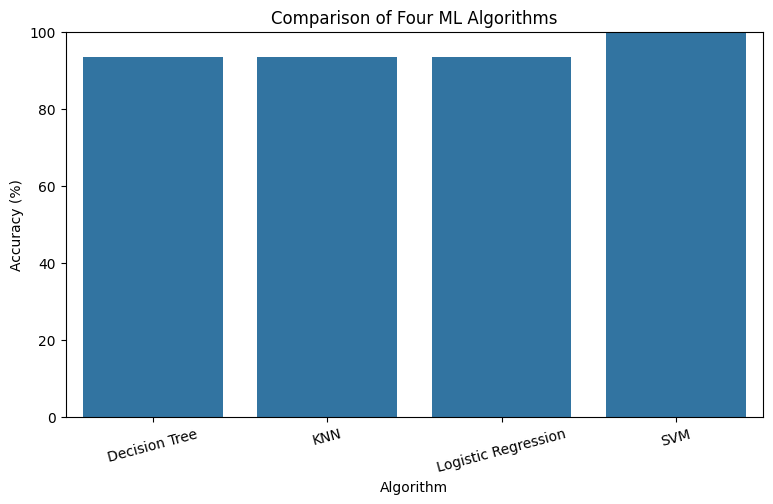

In [10]:
results_df = pd.DataFrame(results)

display(results_df)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=results_df,
    x="Algorithm",
    y="Accuracy"
)

plt.title("Comparison of Four ML Algorithms")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.show()


 Decision Tree
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



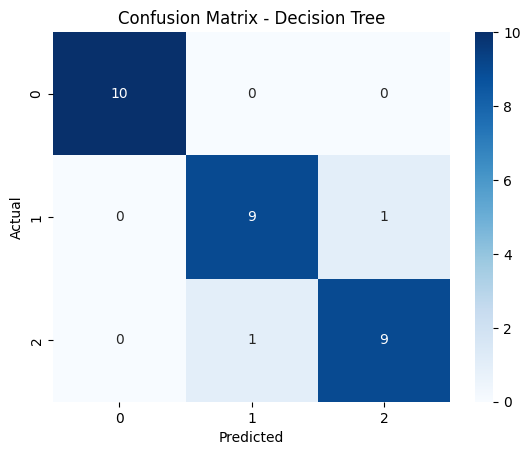


 KNN
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30



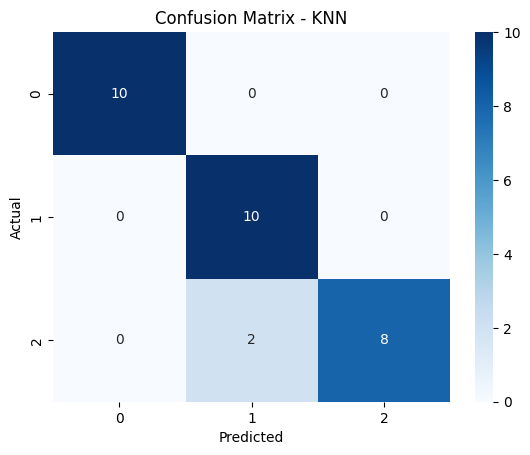


 Logistic Regression
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



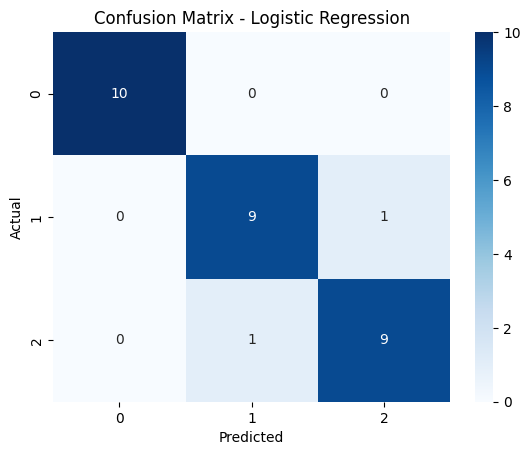


 SVM
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00        10
 Iris-virginica       1.00      1.00      1.00        10

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



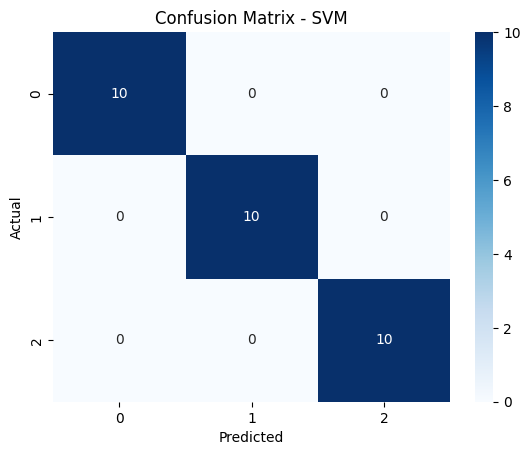

In [11]:
from sklearn.metrics import classification_report, confusion_matrix

for name, model in models.items():
    predictions = model.predict(X_test)

    print("\n", name)
    print(classification_report(y_test, predictions))

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [12]:
new_flower = pd.DataFrame([{
    "SepalLengthCm": 5.1,
    "SepalWidthCm": 3.5,
    "PetalLengthCm": 1.4,
    "PetalWidthCm": 0.2
}])

for name, model in models.items():
    prediction = model.predict(new_flower)[0]
    print(name, "predicts:", prediction)

Decision Tree predicts: Iris-setosa
KNN predicts: Iris-setosa
Logistic Regression predicts: Iris-setosa
SVM predicts: Iris-setosa
